# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pjm

SEED = 600
rng = np.random.default_rng(SEED)
FIG = pjm.ROOT / "fig"

print("Python", platform.python_version())
for name, digest in pjm.check_data().items():
    print(f"{name}: SHA-256 matches data/README.md ({digest[:12]}...)")

Python 3.14.3
pjm_hourly.csv: SHA-256 matches data/README.md (864b6b11d2b5...)
weather_daily.csv: SHA-256 matches data/README.md (e658984bb0f2...)
pjm_prices.csv: SHA-256 matches data/README.md (b0fb8020b0b9...)


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


99,384 hours; 9 demand and 1 forecast hours set to missing as spikes
3,957 days from 01 January 2016 to 31 October 2026


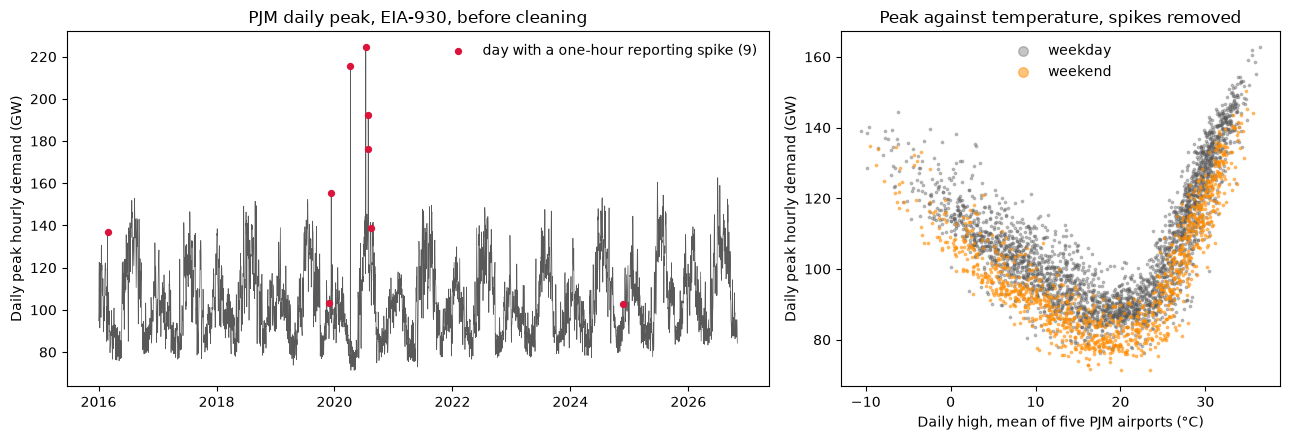

,count,mean,std,min,5%,50%,95%,max
Daily peak demand (GW),3957.0,104.6,17.4,71.3,81.2,101.4,138.0,162.6
PJM day-ahead forecast of the peak (GW),3942.0,104.3,17.3,71.4,81.2,101.2,137.7,165.6
PJM forecast error of the peak (%),3942.0,0.4,2.3,-11.6,-3.6,0.5,4.0,9.7
"Daily high, five-airport mean (°C)",3957.0,18.3,10.2,-10.6,0.9,19.6,32.0,36.4
"Daily low, five-airport mean (°C)",3957.0,8.5,9.4,-19.3,-6.8,8.5,21.8,25.4


In [2]:
hourly = pjm.load_hourly()
weather = pjm.load_weather()
days = pjm.daily(hourly, weather)
print(f"{len(hourly):,} hours; {hourly['demand_spike'].sum()} demand and "
      f"{hourly['forecast_spike'].sum()} forecast hours set to missing as spikes")
print(f"{len(days):,} days from {days.index.min():%d %B %Y} to {days.index.max():%d %B %Y}")

# The daily maximum before the spikes are removed, so the plot shows what was dropped.
raw_peak = hourly.groupby("date")["demand_adjusted_mw"].max()
raw_peak = raw_peak[raw_peak.index >= pjm.ANALYSIS_START]
spikes = raw_peak[raw_peak.index.isin(hourly.loc[hourly["demand_spike"], "date"])]
weekend = days["weekday"] >= 5

fig, (ax_time, ax_temp) = plt.subplots(
    1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax_time.plot(raw_peak.index, raw_peak / 1000, lw=0.5, color="0.35")
ax_time.scatter(spikes.index, spikes / 1000, s=18, color="crimson", zorder=3,
                label=f"day with a one-hour reporting spike ({len(spikes)})")
ax_time.set(ylabel="Daily peak hourly demand (GW)",
            title="PJM daily peak, EIA-930, before cleaning")
ax_time.legend(loc="upper right", frameon=False)

ax_temp.scatter(days.loc[~weekend, "tmax_c"], days.loc[~weekend, "peak_mw"] / 1000,
                s=3, alpha=0.35, color="0.35", label="weekday")
ax_temp.scatter(days.loc[weekend, "tmax_c"], days.loc[weekend, "peak_mw"] / 1000,
                s=3, alpha=0.5, color="darkorange", label="weekend")
ax_temp.set(xlabel="Daily high, mean of five PJM airports (°C)",
            ylabel="Daily peak hourly demand (GW)", title="Peak against temperature, spikes removed")
ax_temp.legend(loc="upper center", frameon=False, markerscale=4)

fig.tight_layout()
fig.savefig(FIG / "raw_daily_peak.png", dpi=150)
plt.show()

summary = pd.DataFrame({
    "Daily peak demand (GW)": days["peak_mw"] / 1000,
    "PJM day-ahead forecast of the peak (GW)": days["forecast_peak_mw"] / 1000,
    "PJM forecast error of the peak (%)": 100 * (days["peak_mw"] / days["forecast_peak_mw"] - 1),
    "Daily high, five-airport mean (°C)": days["tmax_c"],
    "Daily low, five-airport mean (°C)": days["tmin_c"],
})
summary.describe(percentiles=[0.05, 0.5, 0.95]).T.round(1)

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [3]:
days = pjm.add_known_the_day_before(days)
days = days.join(pjm.peak_hour_prices(hourly, pjm.load_prices()))  # $/MWh in the hour of each day's peak
train, valid, held_out = pjm.split(days)
fit = pd.concat([train, valid])  # refit on both before the one held-out score

pd.DataFrame({
    "first day": [s.index.min().date() for s in (train, valid, held_out)],
    "last day": [s.index.max().date() for s in (train, valid, held_out)],
    "days": [len(s) for s in (train, valid, held_out)],
    "use": ["fit the model", "choose between methods", "score once, never fitted"],
}, index=["training", "validation", "held-out"])

,first day,last day,days,use
training,2016-01-03,2023-12-31,2898,fit the model
validation,2024-01-01,2024-12-31,362,choose between methods
held-out,2025-01-01,2026-10-31,665,"score once, never fitted"


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [4]:
# Costs from PJM's peak-hour prices on the training days only (decisions.md, 2026-11-27).
cost_short, cost_long = pjm.estimate_costs(train)
assert np.allclose([cost_short, cost_long], [pjm.COST_SHORT, pjm.COST_LONG], atol=0.005)
ALPHA = pjm.critical_fractile()
print(f"Training days: c_u = ${cost_short:.2f}/MWh short, c_o = ${cost_long:.2f}/MWh long, "
      f"so buy the {ALPHA:.3f} quantile of tomorrow's peak.")

# How much the estimate leans on a few spike days.
spread = train["lmp_rt"] - train["lmp_da"]
was_short = train["peak_mw"] > train["forecast_peak_mw"]
largest = spread.nlargest(3)
low, high = spread.quantile([0.01, 0.99])
cost_checks = {}
for name, s in {
    "all training days": spread,
    f"without the 3 largest spreads ({', '.join(f'{d:%d %b %Y}' for d in largest.index)})": spread.drop(largest.index),
    "spreads clipped at their 1% and 99% quantiles": spread.clip(low, high),
}.items():
    c_u, c_o = s[was_short.reindex(s.index)].mean(), -s[~was_short.reindex(s.index)].mean()
    cost_checks[name] = {"c_u ($/MWh)": c_u, "c_o ($/MWh)": c_o, "τ": c_u / (c_u + c_o)}
cost_checks["median spread"] = {"c_u ($/MWh)": spread[was_short].median(), "c_o ($/MWh)": -spread[~was_short].median(),
                                "τ": float("nan")}
display(pd.DataFrame(cost_checks).T.round(3))


def score(rules, days):
    """Mean dollars lost per day on the peak hour, and how often the buyer came up short."""
    return pd.DataFrame({
        "mean cost ($/day)": {name: pjm.cost(bought, days["peak_mw"]).mean() for name, bought in rules.items()},
        "days short (%)": {name: 100 * (days["peak_mw"] > bought).mean() for name, bought in rules.items()},
    })


def baselines(days):
    return {
        "Buy PJM's forecast of the peak": days["forecast_peak_mw"],
        "Buy the peak two days before": days["peak_lag2_mw"],
    }


score(baselines(held_out), held_out).round(1)

Training days: c_u = $7.75/MWh short, c_o = $6.34/MWh long, so buy the 0.550 quantile of tomorrow's peak.


,c_u ($/MWh),c_o ($/MWh),τ
all training days,7.749,6.342,0.550
"without the 3 largest spreads (24 Dec 2022, 23 Dec 2022, 13 Jun 2022)",4.749,6.342,0.428
spreads clipped at their 1% and 99% quantiles,3.369,5.943,0.362
median spread,-3.044,6.128,NaN


,mean cost ($/day),days short (%)
Buy PJM's forecast of the peak,15202.8,59.4
Buy the peak two days before,63061.5,48.6


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


Let $Q_D$ be the peak hourly demand on day $D$ in GW, and $F_D$ PJM's day-ahead forecast of it. On the morning of day $D-1$ the buyer knows $F_D$ and everything up to the end of day $D-2$. The model gives the $\tau$ quantile of tomorrow's peak:

$$
q_\tau(Q_D) = \beta_0 + \beta_1 F_D + \beta_2 (F_D - 110)^+ + \beta_3\,\text{weekend}_D + \beta_4 (Q_{D-2} - F_{D-2}) + \beta_5\,\text{holiday}_D + \beta_6\,\text{early summer}_D
$$

- $\beta_1$: how much of PJM's forecast carries through. Near 1 means PJM's forecast is about right in scale.
- $\beta_2$: an extra slope above 110 GW. Hot and cold days are where PJM's misses are largest, so the quantile can move away from the forecast there.
- $\beta_3$: weekend shift, since weekend load is lower and shaped differently.
- $\beta_4$: how much of PJM's miss two days ago persists. It picks up slow bias, such as unmetered rooftop solar that PJM's forecast has not caught up with.
- $\beta_5$: holiday shift, on weekday holidays when load drops: New Year's Day, Memorial Day, 4 July, Labor Day, Thanksgiving and the Friday after, Christmas Eve, and Christmas. PJM's forecast runs high on these days.
- $\beta_6$: early-summer shift, on days from 15 May to 20 June when PJM forecasts at least 110 GW. The first heat of the year is where PJM's forecast runs low most often.
- $\beta_0$, together with fitting at $\tau$ rather than the mean, sets the margin above the forecast that the costs ask for.

The coefficients minimize the pinball loss $\sum_D \rho_\tau(Q_D - q_\tau)$ with $\rho_\tau(u) = u\,(\tau - \mathbb{1}[u<0])$, solved exactly as a linear program. With $\tau = c_u/(c_u+c_o)$, minimizing the pinball loss is the same as minimizing the buyer's expected cost, so the model's quantile is the purchase.

Every input is known on the morning before: the calendar, PJM's forecast, and the days up to $D-2$. We added $\beta_5$ and $\beta_6$ after the first version of this model, chose them on the 2024 validation year, and set the early-summer threshold at the existing 110 GW knot rather than tuning it. The pattern that suggested them showed up in a check that included held-out days, so the held-out score below is not fully blind to them (decisions.md, 2026-11-27).

**The assumption we trust least:** that PJM's day-ahead forecast in EIA-930 is the one a buyer had on the morning before. EIA reports it as the day-ahead forecast, but we have not checked when PJM issues it. The model does not use observed temperature, because the buyer only has a temperature forecast, and we do not have archived temperature forecasts; PJM's forecast carries its own weather forecast.

In [5]:
COEFFICIENTS = ["β0 intercept (GW)", "β1 PJM forecast", "β2 forecast above 110 GW",
                "β3 weekend (GW)", "β4 PJM miss two days before", "β5 holiday (GW)",
                "β6 early summer (GW)"]
FIRST_FIVE = 5  # the inputs before the holiday and early-summer shifts


def rules(fit_days, days):
    """Every purchase rule, fitted on fit_days and applied to days."""
    beta = pjm.fit_quantile(pjm.design(fit_days), fit_days["peak_mw"].to_numpy() / 1000, ALPHA)
    beta_five = pjm.fit_quantile(pjm.design(fit_days)[:, :FIRST_FIVE], fit_days["peak_mw"].to_numpy() / 1000, ALPHA)
    margin = np.quantile(fit_days["peak_mw"] / fit_days["forecast_peak_mw"], ALPHA)
    return beta, {
        **baselines(days),
        f"Buy PJM's forecast × {margin:.3f} (its {ALPHA:.2f} quantile margin)": days["forecast_peak_mw"] * margin,
        "Buy the model's quantile, first five inputs": pd.Series(pjm.design(days)[:, :FIRST_FIVE] @ beta_five * 1000,
                                                              index=days.index),
        "Buy the model's quantile": pd.Series(pjm.design(days) @ beta * 1000, index=days.index),
    }


# Choose on the validation year, with the fit on training days only.
_, on_valid = rules(train, valid)
print("Validation year 2024")
display(score(on_valid, valid).round(1))

# Refit on training and validation days, then score the held-out days once.
beta, on_held_out = rules(fit, held_out)
held_out_scores = score(on_held_out, held_out)
print("Held-out days, January 2025 to October 2026")
display(held_out_scores.round(1))

# Uncertainty: an 80% interval from the 0.1 and 0.9 quantiles, and how often it held.
low, high = (pjm.design(held_out) @ pjm.fit_quantile(pjm.design(fit), fit["peak_mw"].to_numpy() / 1000, tau) * 1000
             for tau in (0.1, 0.9))
inside = ((held_out["peak_mw"] >= low) & (held_out["peak_mw"] <= high)).mean()
print(f"80% interval: median width {np.median(high - low) / 1000:.1f} GW; "
      f"held-out peaks inside it on {100 * inside:.1f}% of days")

pd.Series(beta, index=COEFFICIENTS, name=f"fitted at τ = {ALPHA:.3f}").round(3).to_frame()

Validation year 2024


,mean cost ($/day),days short (%)
Buy PJM's forecast of the peak,12998.5,61.9
Buy the peak two days before,60115.9,49.7
Buy PJM's forecast × 1.007 (its 0.55 quantile margin),12043.4,45.0
"Buy the model's quantile, first five inputs",12131.4,46.1
Buy the model's quantile,11956.3,45.6


Held-out days, January 2025 to October 2026


,mean cost ($/day),days short (%)
Buy PJM's forecast of the peak,15202.8,59.4
Buy the peak two days before,63061.5,48.6
Buy PJM's forecast × 1.007 (its 0.55 quantile margin),14368.0,47.2
"Buy the model's quantile, first five inputs",14003.8,48.3
Buy the model's quantile,13984.6,47.7


80% interval: median width 6.3 GW; held-out peaks inside it on 79.1% of days


,fitted at τ = 0.550
β0 intercept (GW),-0.684
β1 PJM forecast,1.014
β2 forecast above 110 GW,-0.043
β3 weekend (GW),0.041
β4 PJM miss two days before,0.152
β5 holiday (GW),-1.417
β6 early summer (GW),0.825


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


The model says only where the $\tau$ quantile sits. To simulate from it we need the whole distribution, so the check uses the simplest one consistent with it: tomorrow's peak is the median model plus normal noise with constant spread,

$$
Q_D = x_D^\top \beta_{0.5} + \sigma \varepsilon_D, \qquad \varepsilon_D \sim N(0, 1),
$$

with $\beta_{0.5}$ the median fit on the 2016 to 2024 days and $\sigma$ the robust spread of its residuals (1.4826 times the median absolute residual). Under that model the true $\tau$ quantile has the same slopes as $\beta_{0.5}$ and an intercept higher by $\sigma\,\Phi^{-1}(\tau)$, so the true coefficients at the purchase quantile $\tau$ are known. We draw 50 data sets on the real inputs, refit each at $\tau$, and check that the fit recovers those coefficients. Then we compare the simulated residuals with the real ones, which tests the noise assumption itself. The draws use the notebook's seed, 600.

Median model noise: sigma = 2.10 GW


,true,mean of 50 fits,sd of the fits,true within mean ± 2 sd,fitted on real data
β0 intercept (GW),0.310,0.303,0.521,True,-0.684
β1 PJM forecast,1.004,1.004,0.005,True,1.014
β2 forecast above 110 GW,-0.035,-0.035,0.010,True,-0.043
β3 weekend (GW),-0.051,-0.052,0.102,True,0.041
β4 PJM miss two days before,0.165,0.163,0.018,True,0.152
β5 holiday (GW),-1.710,-1.641,0.366,True,-1.417
β6 early summer (GW),0.772,0.788,0.263,True,0.825


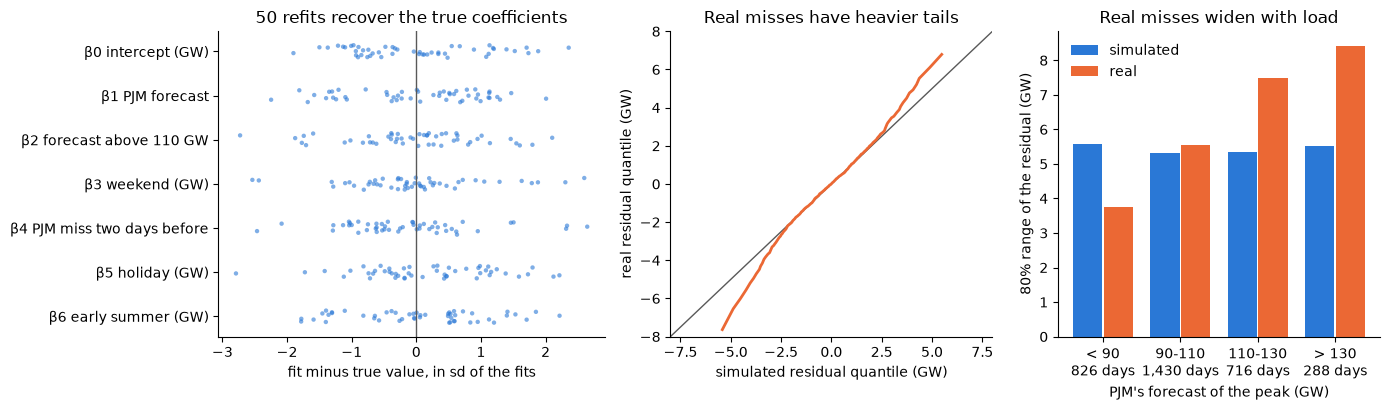

,real,simulated,days
< 90,3.76,5.56,826
90-110,5.53,5.31,1430
110-130,7.49,5.35,716
> 130,8.42,5.53,288


In [6]:
from scipy import stats

X_fit = pjm.design(fit)
y_fit = fit["peak_mw"].to_numpy() / 1000
beta_median = pjm.fit_quantile(X_fit, y_fit, 0.5)
resid_median = y_fit - X_fit @ beta_median
sigma = 1.4826 * np.median(np.abs(resid_median))
beta_true = beta_median.copy()
beta_true[0] += sigma * stats.norm.ppf(ALPHA)

N_SIM = 50
recovered = np.array([
    pjm.fit_quantile(X_fit, X_fit @ beta_median + sigma * rng.standard_normal(len(y_fit)), ALPHA)
    for _ in range(N_SIM)
])
spread = recovered.std(axis=0)
recovery = pd.DataFrame({
    "true": beta_true,
    f"mean of {N_SIM} fits": recovered.mean(axis=0),
    "sd of the fits": spread,
    "true within mean ± 2 sd": np.abs(recovered.mean(axis=0) - beta_true) <= 2 * spread,
    "fitted on real data": beta,
}, index=COEFFICIENTS)
print(f"Median model noise: sigma = {sigma:.2f} GW")
display(recovery.round(3))

# Real against simulated residuals of the median model: overall shape, and spread by load.
simulated = sigma * rng.standard_normal(len(y_fit))
probs = np.linspace(0.005, 0.995, 199)
load_bins = pd.cut(X_fit[:, 1], [0, 90, 110, 130, 200], labels=["< 90", "90-110", "110-130", "> 130"])


def width_80(r):
    return np.subtract(*np.quantile(r, [0.9, 0.1]))


widths = pd.DataFrame({
    "real": pd.Series(resid_median).groupby(load_bins, observed=True).apply(width_80),
    "simulated": pd.Series(simulated).groupby(load_bins, observed=True).apply(width_80),
    "days": pd.Series(resid_median).groupby(load_bins, observed=True).size(),
})

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "0.35"
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.2, 1, 1]})

ax = axes[0]
standardized = (recovered - beta_true) / spread
ax.axvline(0, color=INK, lw=1)
for k, name in enumerate(COEFFICIENTS):
    ax.scatter(standardized[:, k], np.full(N_SIM, k) + rng.uniform(-0.15, 0.15, N_SIM),
               s=10, color=BLUE, alpha=0.6, edgecolor="none")
ax.set(yticks=range(len(COEFFICIENTS)), yticklabels=COEFFICIENTS, xlabel="fit minus true value, in sd of the fits",
       title=f"{N_SIM} refits recover the true coefficients")
ax.invert_yaxis()

ax = axes[1]
lim = 8
ax.plot([-lim, lim], [-lim, lim], color=INK, lw=1)
ax.plot(np.quantile(simulated, probs), np.quantile(resid_median, probs), color=ORANGE, lw=2)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="simulated residual quantile (GW)",
       ylabel="real residual quantile (GW)", title="Real misses have heavier tails")

ax = axes[2]
x = np.arange(len(widths))
ax.bar(x - 0.2, widths["simulated"], 0.38, color=BLUE, label="simulated")
ax.bar(x + 0.2, widths["real"], 0.38, color=ORANGE, label="real")
ax.set(xticks=x, xticklabels=[f"{b}\n{n:,} days" for b, n in zip(widths.index, widths["days"])],
       xlabel="PJM's forecast of the peak (GW)", ylabel="80% range of the residual (GW)",
       title="Real misses widen with load")
ax.legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "simulation_check.png", dpi=150)
plt.show()
widths.round(2)

**What the check shows.** The fit recovers known coefficients. Across 50 simulated data sets, the mean of each of the seven refits is within two standard deviations of its true value, with no visible bias (left panel), so the linear program and the design matrix do what the equations say. The holiday and early-summer shifts are the least precise, with standard deviations of 0.37 and 0.26 GW, because they rest on 64 and 111 of the 3,260 fit days.

The simulated data differ from the real data in two ways, and both are failures of the constant-spread normal noise, not of the quantile fit:

- **Heavier tails.** The 1% and 99% quantiles of the real median-model residuals are about −6.5 and +6.1 GW, against about ±4.9 GW for the normal (middle panel).
- **Spread grows with load.** The 80% range of the real residuals is 3.8 GW on days PJM forecast below 90 GW and 8.4 GW above 130 GW. The simulation keeps it near 5.5 GW everywhere (right panel).

Quantile regression does not assume normal noise, and fitting at $\tau$ lets the slopes differ from the median's, so the purchase rule can still be right. The next section checks whether it is, on the high-load days where a miss costs the most.

## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


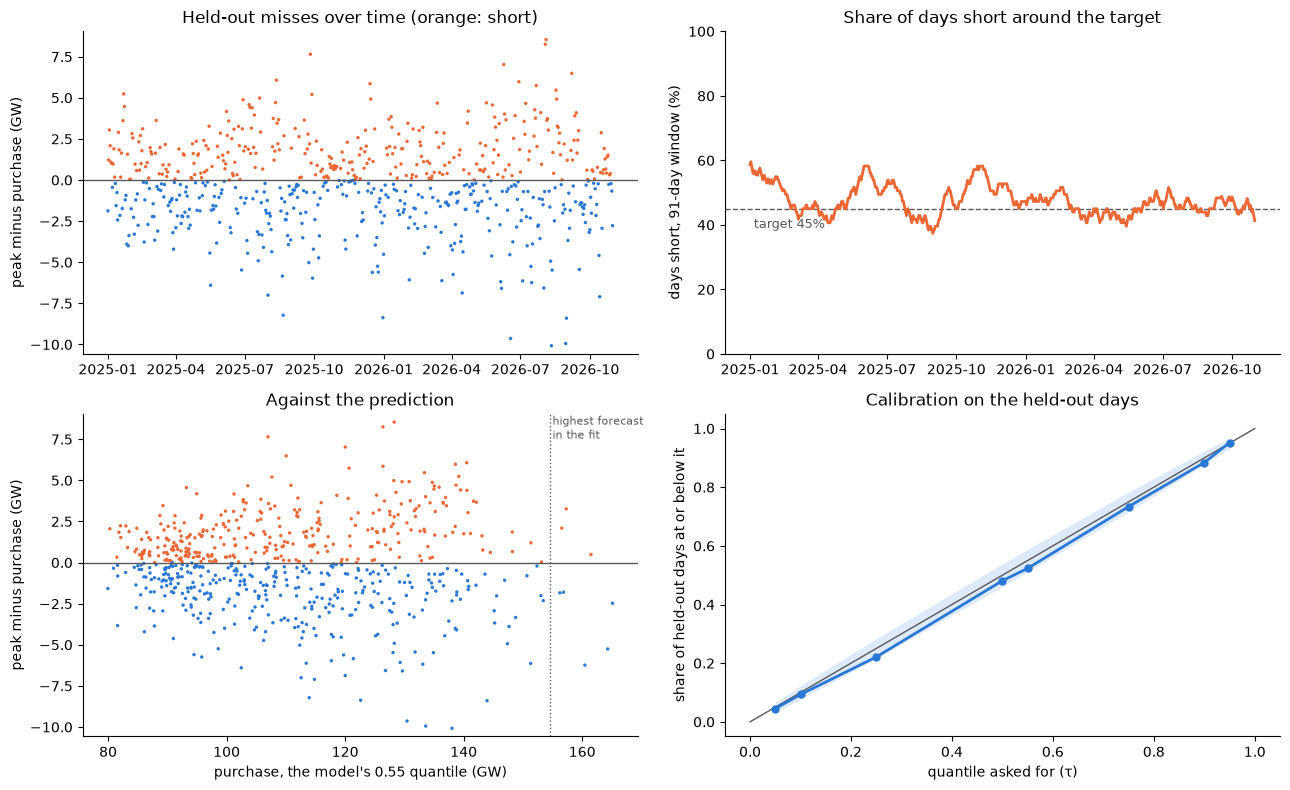

Short on 47.7% of 665 held-out days; the rule aims for 45.0%.


τ,0.05,0.10,0.25,0.50,0.55,0.75,0.90,0.95
share at or below,0.045,0.093,0.221,0.481,0.523,0.734,0.884,0.952
± 2 se,0.017,0.023,0.034,0.039,0.039,0.034,0.023,0.017


days  short_pct  mean_resid_gw  mean_abs_resid_gw  \
year          2025      363      48.48          -0.16               1.87   
              2026      302      46.69          -0.25               2.17   
forecast (GW) 110-130   193      43.52          -0.50               2.50   
              90-110    268      50.00          -0.08               1.63   
              < 90       96      47.92          -0.07               1.14   
              > 130     108      49.07          -0.05               2.81   
season        fall      150      50.00          -0.12               1.56   
              spring    182      41.76          -0.44               1.68   
              summer    184      48.37          -0.13               2.75   
              winter    149      51.68          -0.06               1.94   

                       cost_per_day  
year          2025         13029.78  
              2026         15132.33  
forecast (GW) 110-130      17234.38  
              90-110       11459.53  
              < 90          7996.70  
              > 130        19765.75  
season        fall         10902.45  
              spring       11492.46  
              summer       19258.61  
              winter       13618.76

In [7]:
# Held-out residuals of the purchase rule: peak minus the model's tau quantile. Positive means short.
bought_gw = pd.Series(pjm.design(held_out) @ beta, index=held_out.index)
resid = held_out["peak_mw"] / 1000 - bought_gw
short = resid > 0
TARGET = 1 - ALPHA

# Calibration: refit at each tau on 2016-2024 and count held-out days at or below the quantile.
taus = np.sort([0.05, 0.1, 0.25, 0.5, ALPHA, 0.75, 0.9, 0.95])
X_held = pjm.design(held_out)
y_held = held_out["peak_mw"].to_numpy() / 1000
observed = np.array([(y_held <= X_held @ pjm.fit_quantile(X_fit, y_fit, t)).mean() for t in taus])
band = 2 * np.sqrt(taus * (1 - taus) / len(y_held))  # binomial, ignoring day-to-day correlation

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.ravel()

ax = axes[0]
ax.axhline(0, color=INK, lw=1)
ax.scatter(resid.index, resid, s=6, color=np.where(short, ORANGE, BLUE), edgecolor="none")
ax.set(ylabel="peak minus purchase (GW)", ylim=(resid.min() - 0.5, resid.max() + 0.5),
       title="Held-out misses over time (orange: short)")

ax = axes[1]
rolling = short.astype(float).rolling(91, center=True, min_periods=45).mean()
ax.axhline(100 * TARGET, color=INK, lw=1, ls="--")
ax.text(rolling.index[5], 100 * TARGET - 3, f"target {TARGET:.0%}", fontsize=9, color=INK, va="top")
ax.plot(rolling.index, 100 * rolling, color=ORANGE, lw=2)
ax.set(ylabel="days short, 91-day window (%)", ylim=(0, 100), title="Share of days short around the target")

ax = axes[2]
ax.axhline(0, color=INK, lw=1)
ax.scatter(bought_gw, resid, s=6, color=np.where(short, ORANGE, BLUE), edgecolor="none")
ax.axvline(fit["forecast_peak_mw"].max() / 1000, color=INK, lw=1, ls=":")
ax.text(fit["forecast_peak_mw"].max() / 1000 + 0.5, resid.max() - 1, "highest forecast\nin the fit", fontsize=8, color=INK)
ax.set(xlabel=f"purchase, the model's {ALPHA:.2f} quantile (GW)", ylabel="peak minus purchase (GW)",
       ylim=(resid.min() - 0.5, resid.max() + 0.5),
       title="Against the prediction")

ax = axes[3]
ax.plot([0, 1], [0, 1], color=INK, lw=1)
ax.fill_between(taus, taus - band, taus + band, color=BLUE, alpha=0.15, lw=0)
ax.plot(taus, observed, "o-", color=BLUE, lw=2, ms=5)
ax.set(xlabel="quantile asked for (τ)", ylabel="share of held-out days at or below it",
       title="Calibration on the held-out days")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "residuals_calibration.png", dpi=150)
plt.show()

print(f"Short on {short.mean():.1%} of {len(short)} held-out days; the rule aims for {TARGET:.1%}.")
display(pd.DataFrame({"τ": taus, "share at or below": observed, "± 2 se": band}).round(3).set_index("τ").T)

# How the error grows: with time since the fit, with load, and by season.
held = held_out.assign(resid=resid, short=short, abs_resid=resid.abs())
groups = {
    "year": held.index.year.astype(str),
    "forecast (GW)": pd.cut(held["forecast_peak_mw"] / 1000, [0, 90, 110, 130, 200],
                            labels=["< 90", "90-110", "110-130", "> 130"]).astype(str),
    "season": held.index.month.map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                                    6: "summer", 7: "summer", 8: "summer", 9: "fall", 10: "fall", 11: "fall"}),
}
growth = pd.concat({
    name: held.groupby(key).agg(days=("short", "size"), short_pct=("short", "mean"),
                                mean_resid_gw=("resid", "mean"), mean_abs_resid_gw=("abs_resid", "mean"),
                                cost_per_day=("resid", lambda r: pjm.cost(bought_gw[r.index] * 1000,
                                                                          held_out.loc[r.index, "peak_mw"]).mean()))
    for name, key in groups.items()
})
growth["short_pct"] *= 100
growth.round(2)

**Noise or bias.** At the costs from PJM's prices the rule buys the 0.55 quantile, so it aims to come up short on 45% of days. Over the 665 held-out days it was short on 47.7%: 48.5% in 2025 and 46.7% in 2026. The misses show no trend in size over time (top left), and the share of days short wanders around the target (top right). In the calibration check every observed share is within two binomial standard errors of the quantile asked for: 0.481 at τ = 0.5, 0.523 at 0.55, and 0.884 at 0.9. Seven of the eight still sit slightly below, the same small low bias the first version of the model showed, consistent with load growing faster after 2024 than in the training years. It is small next to the noise.

**How the error grows away from the data.**

- **With load.** The mean miss is 1.1 GW on days PJM forecast below 90 GW and 2.8 GW above 130 GW, so those days cost $19,766 a day against $7,997. The share of days short stays between 44% and 50% in every band.
- **Beyond the training range.** PJM's held-out forecasts reach 165.6 GW, above the highest forecast in the fit, 154.5 GW, so on the hottest days the quantile extrapolates β2.
- **With time since the fit.** 2026, a year further from the training data than 2025, has larger misses, 2.17 GW against 1.87 GW, and costs $15,132 a day against $13,030.
- **By season.** Summer costs $19,259 a day, 1.8 times fall's $10,902, and has the largest misses, 2.75 GW on average.

**The two new inputs on the days they target.** On the 29 held-out early-summer days, the model without them was short on 62% of days; with them, 41%, against the 45% target. On the 11 held-out holidays the average over-purchase falls from 2.0 GW to 0.6 GW. These are few days, so the overall held-out cost moves only from $14,004 to $13,985 a day.

**What this means for the purchase.** Hot summer days are where the dollars are. At τ = 0.55 the rule is short on them about as often as on other days, but the misses are larger and a large shortfall costs far more per MWh (next section). Refitting each year on the most recent data would remove the slow low bias.

## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


In [8]:
# How the result moves with the costs. Dollars per day on the held-out days.
cost_cases = {
    "estimated from prices": (pjm.COST_SHORT, pjm.COST_LONG),
    "c_u = c_o": (pjm.COST_LONG, pjm.COST_LONG),
    "c_u = 2 c_o": (2 * pjm.COST_LONG, pjm.COST_LONG),
    "assumed before the prices ($50, $10)": (pjm.ASSUMED_COST_SHORT, pjm.ASSUMED_COST_LONG),
    "c_u = 10 c_o": (10 * pjm.COST_LONG, pjm.COST_LONG),
}
rows = {}
for name, (c_u, c_o) in cost_cases.items():
    tau = pjm.critical_fractile(c_u, c_o)
    beta_tau = pjm.fit_quantile(pjm.design(fit), fit["peak_mw"].to_numpy() / 1000, tau)
    bought = pjm.design(held_out) @ beta_tau * 1000
    pjm_cost = pjm.cost(held_out["forecast_peak_mw"], held_out["peak_mw"], c_u, c_o).mean()
    model_cost = pjm.cost(bought, held_out["peak_mw"], c_u, c_o).mean()
    rows[name] = {
        "c_u": c_u, "c_o": c_o, "τ": tau,
        "buy PJM's forecast ($/day)": pjm_cost,
        "buy the model's quantile ($/day)": model_cost,
        "saved ($/day)": pjm_cost - model_cost,
        "median margin over PJM's forecast (GW)": np.median(bought - held_out["forecast_peak_mw"]) / 1000,
    }
pd.DataFrame(rows).T.round(2)

,c_u,c_o,τ,buy PJM's forecast ($/day),buy the model's quantile ($/day),saved ($/day),median margin over PJM's forecast (GW)
estimated from prices,7.75,6.34,0.55,15202.75,13984.62,1218.13,0.70
c_u = c_o,6.34,6.34,0.50,13396.93,12653.61,743.32,0.44
c_u = 2 c_o,12.68,6.34,0.67,21516.70,17348.29,4168.41,1.38
"assumed before the prices ($50, $10)",50.00,10.00,0.83,72359.62,37177.64,35181.98,2.73
c_u = 10 c_o,63.40,6.34,0.91,86474.84,27525.83,58949.00,3.73


The constant $c_u$ and $c_o$ are averages. The cost of a miss depends on its size, so we also look at the spread by how far PJM missed, and score every rule at each day's own prices instead of the averages.

In [9]:
# The spread grows with the size of PJM's miss: a big shortfall costs far more per MWh than a small one.
def spread_by_miss(days):
    miss_gw = (days["peak_mw"] - days["forecast_peak_mw"]) / 1000
    bins = pd.cut(miss_gw, [-np.inf, -4, -2, 0, 2, 4, np.inf],
                  labels=["long > 4 GW", "long 2-4", "long 0-2", "short 0-2", "short 2-4", "short > 4 GW"])
    spread = days["lmp_rt"] - days["lmp_da"]
    return spread.groupby(bins, observed=True).agg(days="size", mean="mean", median="median")

spread_table = pd.concat({"fit days, 2016-2024": spread_by_miss(fit), "held-out days": spread_by_miss(held_out)}, axis=1)
display(spread_table.round(1))

# Each rule at each day's own prices: (Q - B)(RT - DA) dollars against perfect foresight.
# It can be negative, a gain from being long on a day real time came in cheap.
def at_actual_prices(rules, days):
    spread = days["lmp_rt"] - days["lmp_da"]
    out = {}
    for name, bought in rules.items():
        daily_cost = (days["peak_mw"] - bought) * spread
        out[name] = {"mean ($/day)": daily_cost.mean(),
                     "± 2 se": 2 * daily_cost.std() / np.sqrt(len(daily_cost)),
                     "median ($/day)": daily_cost.median()}
    return pd.DataFrame(out).T

at_actual_prices(on_held_out, held_out).round(0)

fit days, 2016-2024              held-out days             
                            days  mean median          days  mean median
long > 4 GW                  154 -17.4  -12.3            40 -56.9  -29.4
long 2-4                     323  -9.2   -7.8            68  20.3   -9.4
long 0-2                     888  -3.4   -5.2           162 -14.7  -11.2
short 0-2                   1145   0.4   -4.1           213   5.8   -7.2
short 2-4                    548  13.0   -2.1           123  14.8   -1.7
short > 4 GW                 202  31.9    3.8            59  48.0   11.6

,mean ($/day),± 2 se,median ($/day)
Buy PJM's forecast of the peak,53138.0,33546.0,3054.0
Buy the peak two days before,10480.0,116826.0,3084.0
Buy PJM's forecast × 1.007 (its 0.55 quantile margin),50887.0,36642.0,4581.0
"Buy the model's quantile, first five inputs",47329.0,33370.0,4774.0
Buy the model's quantile,46282.0,33252.0,4630.0


**The rule.** Buy the model's 0.55 quantile of tomorrow's peak, a median of 0.7 GW above PJM's forecast on the held-out days. The loss picks 0.55 because at the peak hour on the training days a MWh short cost $7.75 more than buying it day-ahead, and a MWh long lost $6.34: τ = c_u/(c_u + c_o) = 0.55.

**What real prices changed.** The first version assumed that a shortfall costs five times as much as a surplus ($50 against $10). That put the purchase at the 0.83 quantile and showed a saving of $35,182 a day over buying PJM's forecast. Measured from PJM's prices, the two costs are nearly equal. At those costs the model saves $1,218 a day on the held-out days, $13,985 against $15,203, which is 8% and about $810,000 over the 665 days. It beats a fixed margin over PJM's forecast too: the forecast scaled by its 0.55-quantile margin loses $14,368. The proposal's hypothesis, that buying a quantile instead of the point forecast pays, holds, but the payoff is about 30 times smaller than the assumed costs suggested.

**How the action moves with the costs.** If a shortfall cost twice a surplus, the rule would buy 1.4 GW over PJM's forecast and save $4,168 a day. At ten times, it would buy 3.7 GW over and save $58,949 a day. The saving grows fast with the asymmetry, so the estimate of c_u matters more than anything else in the model.

**The cost of a miss depends on its size.** On the fit days when PJM came in more than 4 GW short, real time cost $31.90 per MWh more than day-ahead on average. When it was less than 2 GW short, the gap was $0.40. When PJM was more than 4 GW long, real time came in $17.40 cheaper. The held-out days have the same shape, at $48.00 and −$56.90. So constant costs understate the risk of a big shortfall on a hot day and overstate the cost of a small one.

c_u also leans on a few days. Without Winter Storm Elliott on 23 and 24 December 2022 and the 13 June 2022 spike, c_u falls to $4.75 and τ to 0.43. With spreads clipped at their 1% and 99% quantiles, τ is 0.36. On a typical short day, real time is cheaper than day-ahead (median −$3.04).

**Scored at each day's own prices.** Every rule loses $46,000 to $53,000 a day except buying the peak two days before, at $10,480. The ±2 standard error bands, $33,000 to $117,000, are wider than any gap between the rules: a few spike days decide the ranking, and a rule can come out ahead by being long on days real time happened to be cheap. We report this score and do not choose on it.

**What it is worth to be less wrong.** At these costs each GW of shortfall costs $7,750 at the peak hour, and each GW of surplus $6,340. A perfect forecast would save the whole $15,203 a day that buying PJM's forecast loses; the model captures $1,218 of it. Most of what is left is on summer days, where misses are largest and a shortfall costs the most per MWh. A model that prices big shortfalls by their size, rather than at the average, is where more value is.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
